In [1]:
import json
import time
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create data folder
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Exact 22 Pakistan districts matching backend/data/districts.json
DISTRICTS = [
    {"name": "Lahore", "lat": 31.5204, "lon": 74.3587},
    {"name": "Multan", "lat": 30.1575, "lon": 71.5249},
    {"name": "Faisalabad", "lat": 31.4504, "lon": 73.1350},
    {"name": "Rawalpindi", "lat": 33.5651, "lon": 73.0169},
    {"name": "Peshawar", "lat": 34.0151, "lon": 71.5249},
    {"name": "Quetta", "lat": 30.1798, "lon": 66.9750},
    {"name": "Hyderabad", "lat": 25.3960, "lon": 68.3578},
    {"name": "Sukkur", "lat": 27.7052, "lon": 68.8574},
    {"name": "Bahawalpur", "lat": 29.3956, "lon": 71.6836},
    {"name": "Sialkot", "lat": 32.4945, "lon": 74.5229},
    {"name": "Gujranwala", "lat": 32.1877, "lon": 74.1945},
    {"name": "Sargodha", "lat": 32.0836, "lon": 72.6711},
    {"name": "Dera Ghazi Khan", "lat": 30.0489, "lon": 70.6341},
    {"name": "Larkana", "lat": 27.5570, "lon": 68.2247},
    {"name": "Khairpur", "lat": 27.5295, "lon": 68.7590},
    {"name": "Turbat", "lat": 25.9867, "lon": 63.0440},
    {"name": "Muzaffargarh", "lat": 30.0736, "lon": 71.1930},
    {"name": "Rahim Yar Khan", "lat": 28.4202, "lon": 70.2952},
    {"name": "Jhang", "lat": 31.2681, "lon": 72.3181},
    {"name": "Nawabshah", "lat": 26.2442, "lon": 68.4100},
    {"name": "Karachi", "lat": 24.8607, "lon": 67.0011},
    {"name": "Islamabad", "lat": 33.6844, "lon": 73.0479},
]

# Save pakistan_districts.json
districts_file = DATA_DIR / "pakistan_districts.json"
with open(districts_file, "w", encoding="utf-8") as f:
    json.dump(DISTRICTS, f, indent=2)

print(f"✅ Saved {len(DISTRICTS)} districts to {districts_file}")

✅ Saved 22 districts to data/pakistan_districts.json


In [2]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
PARAMS = ["PRECTOTCORR", "GWETROOT", "T2M_MAX", "RH2M"]
START_DATE = "20150101"
END_DATE = "20241231"
FILL_VALUE = -999


def fetch_district_nasa_data(name: str, lat: float, lon: float) -> pd.DataFrame:
    """Fetch 10 years of daily NASA POWER data for one district."""
    resp = requests.get(
        POWER_URL,
        params={
            "parameters": ",".join(PARAMS),
            "community": "AG",
            "latitude": round(lat, 2),
            "longitude": round(lon, 2),
            "start": START_DATE,
            "end": END_DATE,
            "format": "JSON",
        },
        timeout=120,
    )
    resp.raise_for_status()
    body = resp.json()

    df = pd.DataFrame(body["properties"]["parameter"])
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df.index.name = "date"

    # Replace NASA -999 missing flag with NaN
    df = df.replace(FILL_VALUE, np.nan)[PARAMS]

    # Match backend/services/nasa_api.py fix for GEOSIT source scaling
    if "GEOSIT" in body.get("header", {}).get("sources", []):
        df["PRECTOTCORR"] /= 24.0

    df["district"] = name
    df["lat"] = lat
    df["lon"] = lon
    return df.reset_index()


all_daily_frames = []
for i, d in enumerate(DISTRICTS, start=1):
    print(f"[{i}/{len(DISTRICTS)}] Fetching NASA POWER data for {d['name']} ({d['lat']}, {d['lon']})...")
    df_dist = fetch_district_nasa_data(d["name"], d["lat"], d["lon"])
    all_daily_frames.append(df_dist)
    time.sleep(0.5)  # Polite pause between API calls

daily_df = pd.concat(all_daily_frames, ignore_index=True)
print(f"\n✅ Total daily records fetched: {len(daily_df):,}")
daily_df.head()

[1/22] Fetching NASA POWER data for Lahore (31.5204, 74.3587)...
[2/22] Fetching NASA POWER data for Multan (30.1575, 71.5249)...
[3/22] Fetching NASA POWER data for Faisalabad (31.4504, 73.135)...
[4/22] Fetching NASA POWER data for Rawalpindi (33.5651, 73.0169)...
[5/22] Fetching NASA POWER data for Peshawar (34.0151, 71.5249)...
[6/22] Fetching NASA POWER data for Quetta (30.1798, 66.975)...
[7/22] Fetching NASA POWER data for Hyderabad (25.396, 68.3578)...
[8/22] Fetching NASA POWER data for Sukkur (27.7052, 68.8574)...
[9/22] Fetching NASA POWER data for Bahawalpur (29.3956, 71.6836)...
[10/22] Fetching NASA POWER data for Sialkot (32.4945, 74.5229)...
[11/22] Fetching NASA POWER data for Gujranwala (32.1877, 74.1945)...
[12/22] Fetching NASA POWER data for Sargodha (32.0836, 72.6711)...
[13/22] Fetching NASA POWER data for Dera Ghazi Khan (30.0489, 70.6341)...
[14/22] Fetching NASA POWER data for Larkana (27.557, 68.2247)...
[15/22] Fetching NASA POWER data for Khairpur (27.5295,

,date,PRECTOTCORR,GWETROOT,T2M_MAX,RH2M,district,lat,lon
0,2015-01-01,0.00,0.41,22.40,35.18,Lahore,31.5204,74.3587
1,2015-01-02,0.00,0.41,23.45,36.47,Lahore,31.5204,74.3587
2,2015-01-03,0.09,0.41,21.31,40.90,Lahore,31.5204,74.3587
3,2015-01-04,0.03,0.41,20.29,36.61,Lahore,31.5204,74.3587
4,2015-01-05,0.00,0.41,20.27,40.09,Lahore,31.5204,74.3587


In [3]:
# 1. Check and clean missing values chronologically within each district (no look-ahead leakage)
print("Missing values before cleaning:")
print(daily_df[PARAMS].isna().sum())

daily_df = daily_df.sort_values(["district", "date"]).reset_index(drop=True)
for col in PARAMS:
    daily_df[col] = daily_df.groupby("district")[col].transform(lambda s: s.ffill().bfill())

print("\nMissing values after cleaning:")
print(daily_df[PARAMS].isna().sum())

# 2. Aggregate to monthly records and build the exact 6 features
daily_df["year"] = daily_df["date"].dt.year
daily_df["month_of_year"] = daily_df["date"].dt.month

# Compute 7-day rolling soil moisture per district before monthly aggregation
daily_df["soil_moisture_7d"] = (
    daily_df.groupby("district")["GWETROOT"]
    .transform(lambda s: s.rolling(window=7, min_periods=1).mean())
)

monthly_df = (
    daily_df.groupby(["district", "lat", "lon", "year", "month_of_year"], as_index=False)
    .agg(
        soil_moisture=("GWETROOT", "mean"),             # Feature 1 in predict.py (30-day avg GWETROOT)
        soil_moisture_7d_end=("soil_moisture_7d", "last"),  # 7-day avg at month end
        rainfall_30d=("PRECTOTCORR", "mean"),           # Feature 2 in predict.py (avg daily rainfall mm)
        rain_30d=("PRECTOTCORR", "sum"),                # Total monthly rainfall (mm)
        temp_max=("T2M_MAX", "mean"),                   # Feature 3 in predict.py (avg daily max temp C)
        humidity=("RH2M", "mean"),                      # Feature 4 in predict.py (avg daily humidity %)
    )
)

# Sort chronologically per district to compute lagged previous month rainfall (Feature 6)
monthly_df = monthly_df.sort_values(["district", "year", "month_of_year"]).reset_index(drop=True)
monthly_df["prev_month_rainfall"] = (
    monthly_df.groupby("district")["rain_30d"].shift(1)
)

# Drop the very first month of each district where prev_month_rainfall is NaN
monthly_df = monthly_df.dropna(subset=["prev_month_rainfall"]).reset_index(drop=True)

# Also include alias columns so both predict.py and feature_builder.py column names work seamlessly
monthly_df["rain_prev_month"] = monthly_df["prev_month_rainfall"]
monthly_df["tmax_mean_30d"] = monthly_df["temp_max"]
monthly_df["humidity_mean_30d"] = monthly_df["humidity"]
monthly_df["month"] = monthly_df["month_of_year"]

# Round numerical columns cleanly
num_cols = [
    "soil_moisture", "soil_moisture_7d_end", "rainfall_30d", "rain_30d",
    "temp_max", "humidity", "prev_month_rainfall", "rain_prev_month",
    "tmax_mean_30d", "humidity_mean_30d"
]
monthly_df[num_cols] = monthly_df[num_cols].round(4)

print(f"\n✅ Engineered monthly dataset shape: {monthly_df.shape}")
monthly_df.head()

Missing values before cleaning:
PRECTOTCORR    0
GWETROOT       0
T2M_MAX        0
RH2M           0
dtype: int64

Missing values after cleaning:
PRECTOTCORR    0
GWETROOT       0
T2M_MAX        0
RH2M           0
dtype: int64

✅ Engineered monthly dataset shape: (2618, 16)


,district,lat,lon,year,month_of_year,soil_moisture,soil_moisture_7d_end,rainfall_30d,rain_30d,temp_max,humidity,prev_month_rainfall,rain_prev_month,tmax_mean_30d,humidity_mean_30d,month
0,Bahawalpur,29.3956,71.6836,2015,2,0.3832,0.3800,0.4068,11.39,26.7868,40.8250,1.58,1.58,26.7868,40.8250,2
1,Bahawalpur,29.3956,71.6836,2015,3,0.4071,0.4014,1.4839,46.00,29.3342,50.2665,11.39,11.39,29.3342,50.2665,3
2,Bahawalpur,29.3956,71.6836,2015,4,0.3970,0.3900,0.7480,22.44,38.7000,32.6807,46.00,46.00,38.7000,32.6807,4
3,Bahawalpur,29.3956,71.6836,2015,5,0.3842,0.3871,0.4423,13.71,43.4319,18.8110,22.44,22.44,43.4319,18.8110,5
4,Bahawalpur,29.3956,71.6836,2015,6,0.3977,0.4229,2.3827,71.48,42.5310,33.6207,13.71,13.71,42.5310,33.6207,6


In [4]:
def compute_drought_labels(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculate Drought Risk Score (0-100) and labels based on NASA agro-climatic indicators:
      - Soil Moisture Deficit (50% weight): Lower GWETROOT -> higher drought stress
      - Rainfall Deficit (25% weight): Low current & previous month rainfall -> higher stress
      - Thermal / Evapotranspiration Stress (15% weight): High T2M_MAX -> higher stress
      - Atmospheric Dryness (10% weight): Low RH2M -> higher stress
    """
    # 1. Soil moisture component (GWETROOT typically ranges 0.08 to 0.65 in Pakistan)
    soil_stress = np.clip(1.0 - (df["soil_moisture"] / 0.55), 0.0, 1.0)

    # 2. Rainfall deficit component (30-day total + lagged previous month total)
    effective_rain = 0.7 * df["rain_30d"] + 0.3 * df["prev_month_rainfall"]
    rain_stress = np.clip(1.0 - (effective_rain / 60.0), 0.0, 1.0)

    # 3. Temperature heat stress component (15°C to 45°C range)
    temp_stress = np.clip((df["temp_max"] - 15.0) / 30.0, 0.0, 1.0)

    # 4. Low humidity component (20% to 80% range)
    humidity_stress = np.clip(1.0 - ((df["humidity"] - 20.0) / 60.0), 0.0, 1.0)

    # Weighted composite drought score (0 to 100)
    raw_score = 100.0 * (
        0.50 * soil_stress
        + 0.25 * rain_stress
        + 0.15 * temp_stress
        + 0.10 * humidity_stress
    )
    df["drought_score"] = np.clip(np.round(raw_score), 0, 100).astype(int)

    # 3-Tier Risk Level (Guide Section 6: 0-30 LOW, 31-65 MEDIUM, 66-100 HIGH)
    df["risk_level"] = pd.cut(
        df["drought_score"],
        bins=[-1, 30, 65, 100],
        labels=["LOW", "MEDIUM", "HIGH"],
    ).astype(str)

    # Multi-class target (0 = LOW, 1 = MEDIUM, 2 = HIGH)
    level_map = {"LOW": 0, "MEDIUM": 1, "HIGH": 2}
    df["risk_class"] = df["risk_level"].map(level_map)

    # Binary drought target (1 = Drought when score >= 55 or HIGH/upper-MEDIUM drought, 0 = Normal)
    # Used by backend/routes/predict.py (model.predict_proba(X)[0][1])
    df["drought"] = (df["drought_score"] >= 55).astype(int)

    return df


monthly_df = compute_drought_labels(monthly_df)

print("Drought Risk Level Counts (LOW / MEDIUM / HIGH):")
print(monthly_df["risk_level"].value_counts())
print("\nBinary Drought Counts (0 = No Drought, 1 = Drought):")
print(monthly_df["drought"].value_counts(normalize=True).round(3))

Drought Risk Level Counts (LOW / MEDIUM / HIGH):
risk_level
MEDIUM    1742
LOW        824
HIGH        52
Name: count, dtype: int64

Binary Drought Counts (0 = No Drought, 1 = Drought):
drought
0    0.77
1    0.23
Name: proportion, dtype: float64


In [5]:
FEATURE_COLS = [
    "soil_moisture",
    "rainfall_30d",
    "temp_max",
    "humidity",
    "month_of_year",
    "prev_month_rainfall",
]

# Data quality assertions
assert monthly_df[FEATURE_COLS].isna().sum().sum() == 0, "Found NaN values in feature columns!"
assert len(monthly_df["district"].unique()) == len(DISTRICTS), "Missing districts in final dataset!"

# Save to CSV
csv_path = DATA_DIR / "historical_data.csv"
monthly_df.to_csv(csv_path, index=False)

print(f"✅ Saved clean labeled dataset to: {csv_path}")
print(f"   Total rows: {len(monthly_df):,}")
print(f"   Columns: {list(monthly_df.columns)}\n")
print("Summary Statistics for the 6 Core ML Features:")
display(monthly_df[FEATURE_COLS + ["drought_score", "drought"]].describe().round(3))

✅ Saved clean labeled dataset to: data/historical_data.csv
   Total rows: 2,618
   Columns: ['district', 'lat', 'lon', 'year', 'month_of_year', 'soil_moisture', 'soil_moisture_7d_end', 'rainfall_30d', 'rain_30d', 'temp_max', 'humidity', 'prev_month_rainfall', 'rain_prev_month', 'tmax_mean_30d', 'humidity_mean_30d', 'month', 'drought_score', 'risk_level', 'risk_class', 'drought']

Summary Statistics for the 6 Core ML Features:


,soil_moisture,rainfall_30d,temp_max,humidity,month_of_year,prev_month_rainfall,drought_score,drought
count,2618.000,2618.000,2618.000,2618.000,2618.000,2618.000,2618.000,2618.000
mean,0.455,1.593,33.044,43.450,6.546,48.818,39.076,0.230
std,0.112,2.986,7.904,15.543,3.430,91.731,17.812,0.421
min,0.326,0.000,7.777,11.165,1.000,0.000,1.000,0.000
25%,0.380,0.070,26.846,31.557,4.000,2.102,25.000,0.000
50%,0.422,0.517,33.689,41.415,7.000,15.865,43.000,0.000
75%,0.497,1.792,39.887,54.124,10.000,54.265,54.000,0.000
max,0.950,33.106,47.467,87.033,12.000,993.170,70.000,1.000


/tmp/ipykernel_588/2720362110.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


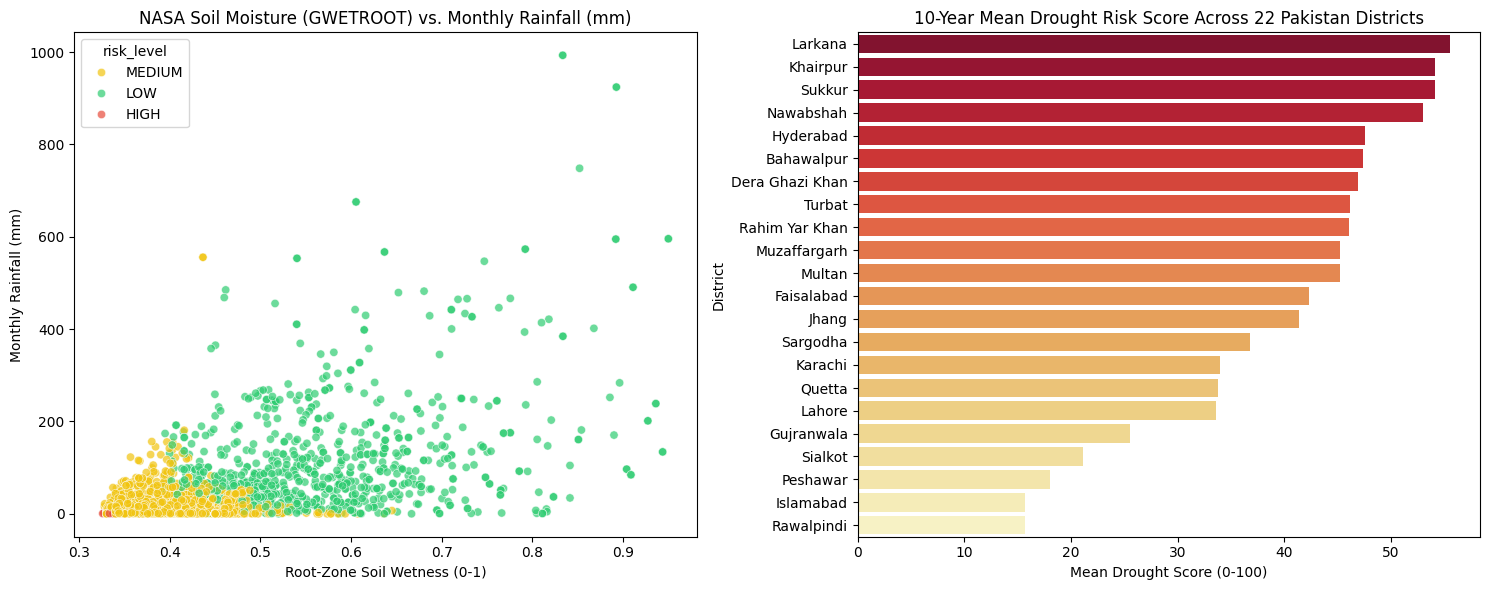

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Soil Moisture vs 30-Day Rainfall colored by Risk Level
palette = {"LOW": "#2ecc71", "MEDIUM": "#f1c40f", "HIGH": "#e74c3c"}
sns.scatterplot(
    data=monthly_df,
    x="soil_moisture",
    y="rain_30d",
    hue="risk_level",
    palette=palette,
    alpha=0.7,
    ax=axes[0],
)
axes[0].set_title("NASA Soil Moisture (GWETROOT) vs. Monthly Rainfall (mm)")
axes[0].set_xlabel("Root-Zone Soil Wetness (0-1)")
axes[0].set_ylabel("Monthly Rainfall (mm)")

# Plot 2: Average Drought Score by District
district_order = (
    monthly_df.groupby("district")["drought_score"]
    .mean()
    .sort_values(ascending=False)
    .index
)
sns.barplot(
    data=monthly_df,
    x="drought_score",
    y="district",
    order=district_order,
    palette="YlOrRd_r",
    errorbar=None,
    ax=axes[1],
)
axes[1].set_title("10-Year Mean Drought Risk Score Across 22 Pakistan Districts")
axes[1].set_xlabel("Mean Drought Score (0-100)")
axes[1].set_ylabel("District")

plt.tight_layout()
plt.show()

In [7]:
try:
    from google.colab import files
    files.download("data/pakistan_districts.json")
    files.download("data/historical_data.csv")
except ImportError:
    print("Running locally — files are already saved in the ./data/ folder!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>